In [3]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

import models

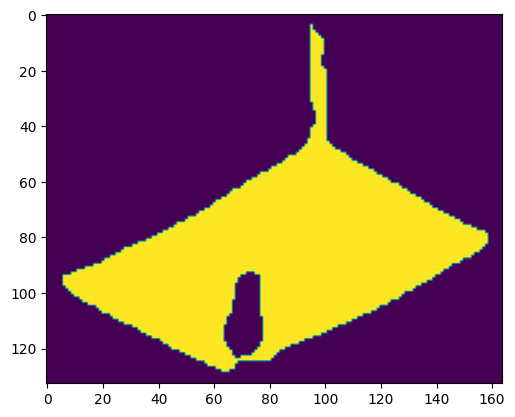

In [5]:
net = models.Segmentator("../fpn/runs/pan_mobilenet_v2_schedule_25_upd_early_stopping/best_upd.onnx")

input_img = cv2.cvtColor(cv2.imread("../theodore_unet/imgs/0000251_0.jpg"), cv2.COLOR_BGR2RGB)
output = net.infer(input_img)
output = np.round(output).astype(np.uint8)

plt.imshow(output)

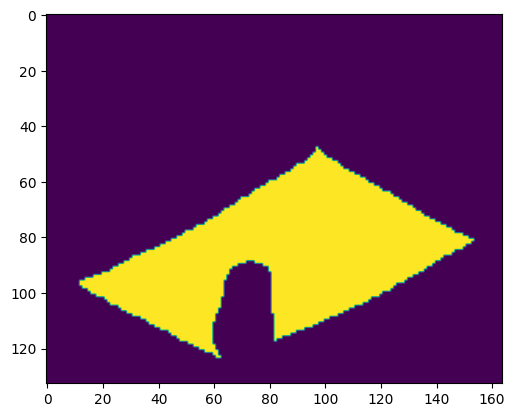

In [15]:
k_size = 9
# kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (k_size, k_size))
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_size, k_size))

res = cv2.erode(output.copy(), kernel, iterations=1)
plt.imshow(res)

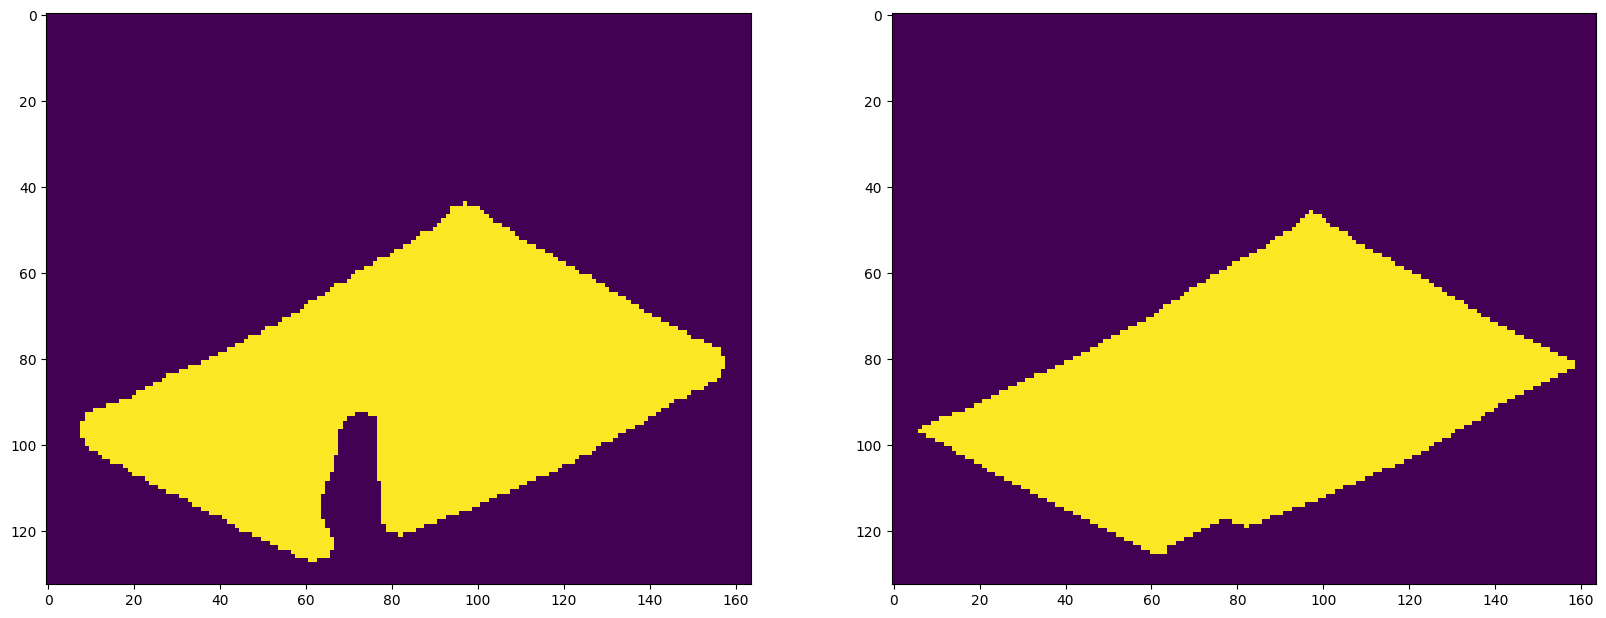

In [58]:
plt.figure(figsize=(20, 10))
k_size = 9
# kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (k_size, k_size))
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_size, k_size))

res = cv2.morphologyEx(output.copy(), cv2.MORPH_OPEN, kernel, iterations=1)
plt.subplot(1, 2, 1)
plt.imshow(res)


k_size = 5
# kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (k_size, k_size))
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_size, k_size))

res = cv2.morphologyEx(res.copy(), cv2.MORPH_CLOSE, kernel, iterations=5)

res = cv2.erode(res, kernel)

plt.subplot(1, 2, 2)
plt.imshow(res)

(64, 1, 2)


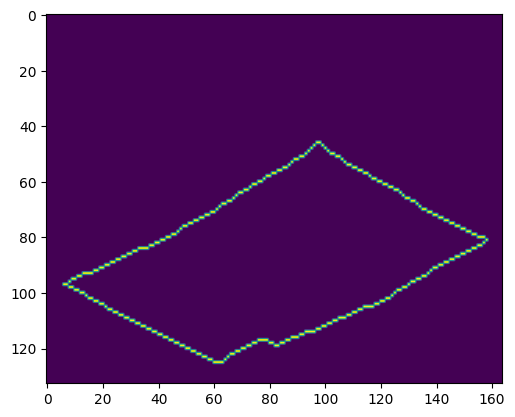

In [79]:
cotour = cv2.findContours(res, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_TC89_L1)
res_contour = cv2.drawContours(res.copy(), cotour[0], 0, (255, 0, 0))
print(cotour[0][0].shape)
plt.imshow(res_contour)

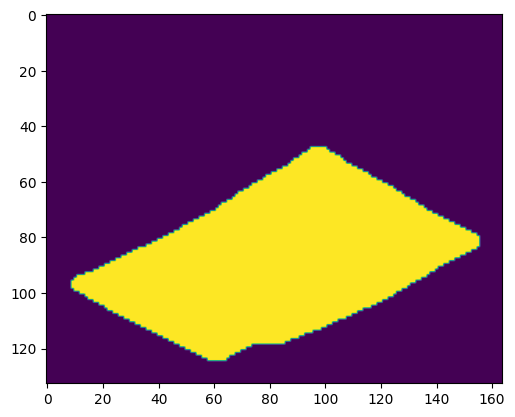

In [111]:
k_size = 9
res_blured = cv2.GaussianBlur(res.copy(), (k_size, k_size), 3)
plt.imshow(res_blured)

(240, 1, 2)


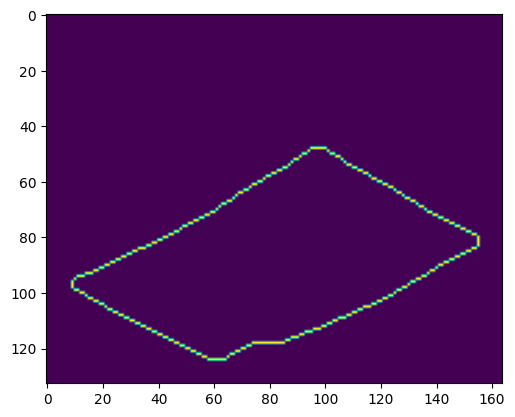

In [113]:
cotour = cv2.findContours(res_blured, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
res_contour = cv2.drawContours(res.copy(), cotour[0], 0, (255, 0, 0))
print(cotour[0][0].shape)
plt.imshow(res_contour)

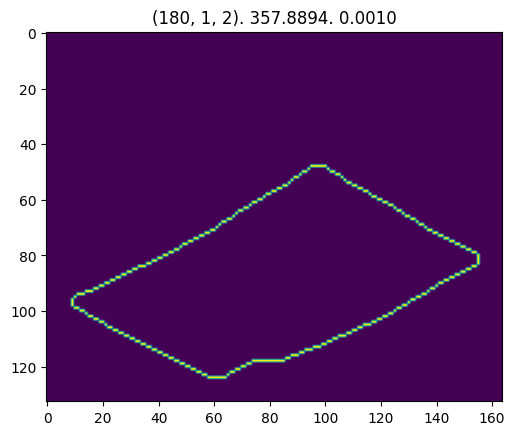

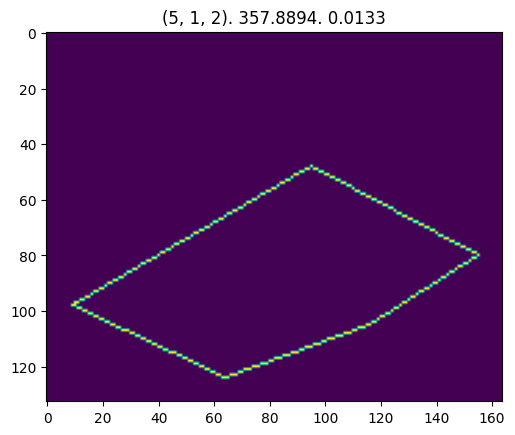

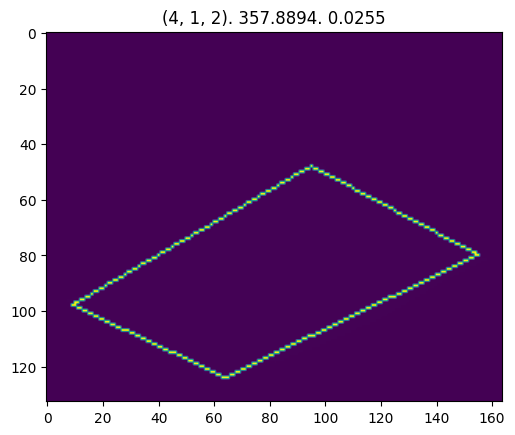

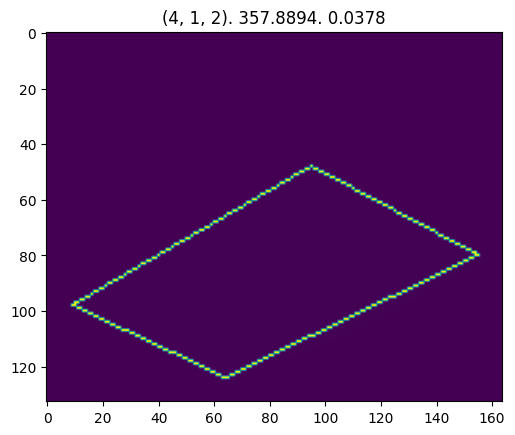

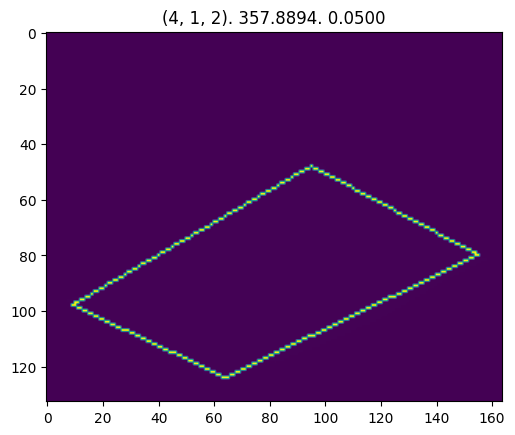

In [120]:
c = cotour[0][0]
for eps in np.linspace(0.001, 0.05, 5):
    peri = cv2.arcLength(c, True)
    approx = cv2.approxPolyDP(c, eps * peri, True)
    
    plt.figure()
    res_contour = cv2.drawContours(res.copy(), [approx], 0, (255, 0, 0))
    plt.imshow(res_contour)
    plt.title(f"{approx.shape}. {peri:.04f}. {eps:.04f}")